In [3]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

In [4]:
def compute_FC(ds_zon_group_velocity, alpha, density_weighted_stat_lwa):

    lat = ds_zon_group_velocity['lat']
    cosphi = np.cos(np.deg2rad(lat)).broadcast_like(ds_zon_group_velocity)
    
    # intermediate
    u = ds_zon_group_velocity - 2*alpha*density_weighted_stat_lwa
    
    #computed FC
    FC = (u**2 * cosphi) / (4.0 * alpha)
    return FC

In [5]:
#ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
ds_clims = []

for experiment in experiments:
    ds = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-51.nc')
    ds_clims.append(ds)

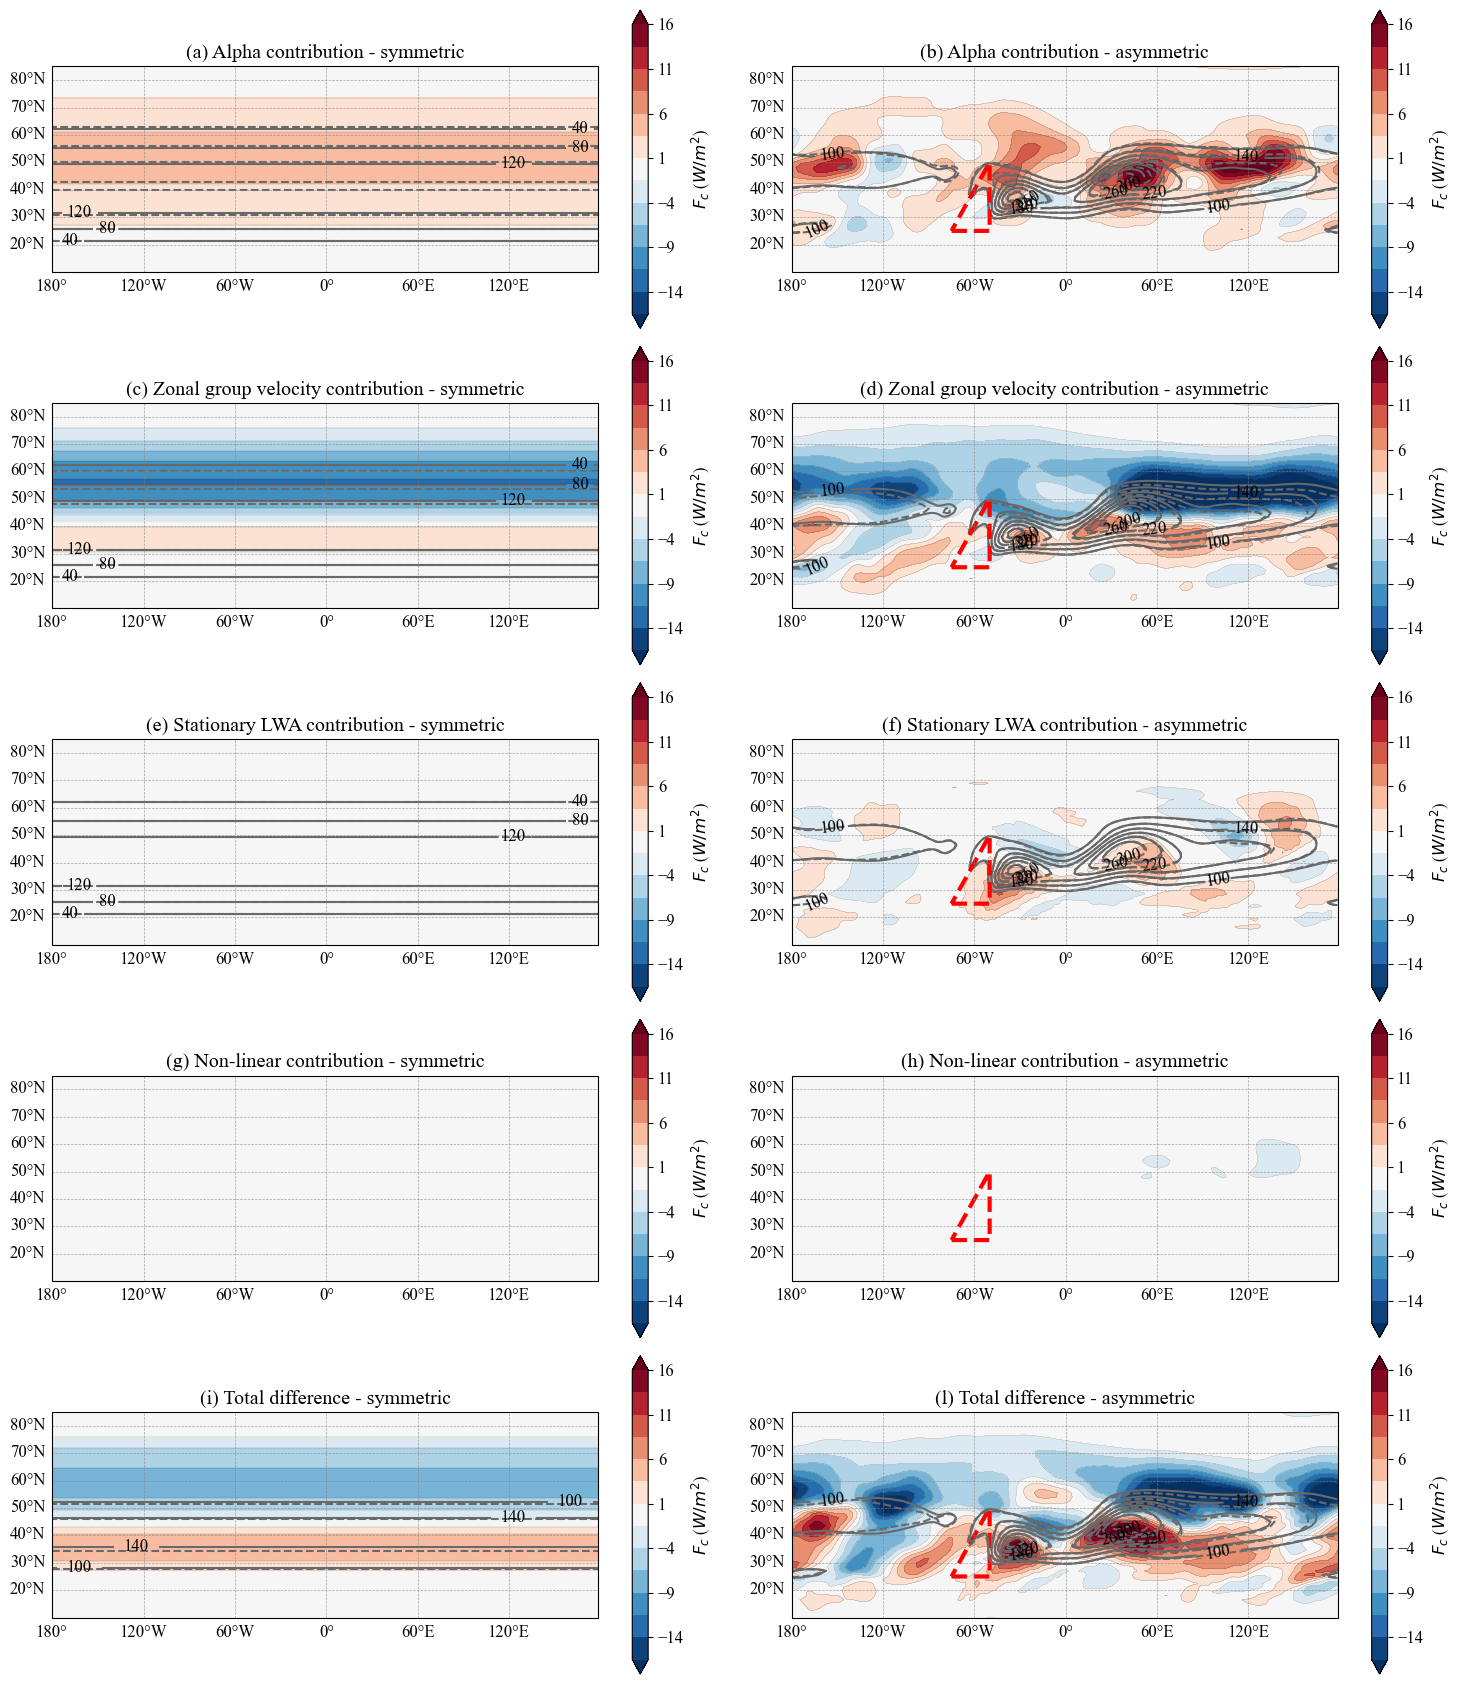

In [12]:
# python
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Set global font family and size
plt.rcParams['font.family'] = 'Times New Roman'      # e.g., 'serif', 'sans-serif', 'monospace'
plt.rcParams['font.size'] = 12             # default font size

# helper to broadcast zonal mean to full lon x lat grid
def broadcast_zonal(field, ds_ref):
    """
    Take zonal mean of 'field' over dim 'lon' and broadcast it to 2D (lat, lon)
    using lon/lat coords from ds_ref. Returns an xarray.DataArray with dims ('lat','lon').
    """
    if 'lon' not in field.dims:
        raise ValueError("Field has no 'lon' dimension to average over.")
    if 'lat' not in field.dims:
        raise ValueError("Field has no 'lat' dimension.")
    # compute zonal mean (lat)
    zonal = field.mean(dim='lon')
    lon = ds_ref['lon']
    lat = zonal['lat']
    # tile to (lat, lon)
    zonal_2d_values = np.tile(zonal.values[:, None], (1, len(lon)))
    zonal_2d = xr.DataArray(
        zonal_2d_values,
        coords={'lat': lat, 'lon': lon},
        dims=('lat', 'lon')
    )
    return zonal_2d

# assume compute_FC and ds_clims are already defined in the notebook scope

# Create transposed layout: 5 rows x 2 columns so each column is one case, last row left empty
fig, ax = plt.subplots(5, 2, figsize=(15, 17), subplot_kw={'projection': ccrs.PlateCarree()})

titles = ['(a) Alpha contribution - symmetric',
          '(b) Alpha contribution - asymmetric',
          '(c) Zonal group velocity contribution - symmetric',
          '(d) Zonal group velocity contribution - asymmetric',
          '(e) Stationary LWA contribution - symmetric',
          '(f) Stationary LWA contribution - asymmetric',
          '(g) Non-linear contribution - symmetric',
          '(h) Non-linear contribution - asymmetric',
          '(i) Total difference - symmetric',
          '(l) Total difference - asymmetric']

# set plot extent to exclude latitudes below 10 and above 85°N and aspect ratio
lon_vals = ds_clims[0]['lon'].values
lonmin, lonmax = float(lon_vals.min()), float(lon_vals.max())
for i,axis in enumerate(ax.flat):
    axis.set_extent([lonmin, lonmax, 10.0, 85.0], crs=ccrs.PlateCarree())
    axis.set_aspect(1.8)
    axis.set_title(titles[i])


titles = ['symmetric', 'asymmetric']
coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

levels = np.arange(40, 400, 40)
levels_diff = np.arange(-16.5, 17, 2.5)

for i in range(2):
    # Column index corresponds to each case; rows 0..3 are the four panels, row 4 left empty
    ax_alpha = ax[0, i]
    ax_zgv = ax[1, i]
    ax_qslwa = ax[2, i]
    ax_spurious = ax[3, i]
    ax_FC = ax[4, i]  # fifth row (empty)

    ds_a = ds_clims[i * 2]
    ds_b = ds_clims[i * 2 + 1]

    spurious_difference = xr.zeros_like(ds_clims[0]['alpha'])
    spurious_field1 = xr.zeros_like(ds_clims[0]['alpha'])
    spurious_field2 = xr.zeros_like(ds_clims[0]['alpha'])

    # alpha contribution
    #ax_alpha.set_title(f'alpha contribution - {titles[i]} : AA (lime) vs Baseline (black)')
    field_1 = compute_FC(ds_a['zgv'], ds_b['alpha'], ds_a['qslwa'])
    field_2 = compute_FC(ds_a['zgv'], ds_a['alpha'], ds_a['qslwa'])

    # choose plotting/accumulation fields: broadcast zonal mean for first column
    if i == 0:
        field_1_plot = broadcast_zonal(field_1, ds_a)
        field_2_plot = broadcast_zonal(field_2, ds_a)
    else:
        field_1_plot = field_1
        field_2_plot = field_2

    spurious_field1 += field_1_plot
    spurious_field2 += field_2_plot
    spurious_difference += (field_1_plot - field_2_plot)

    cont = ax_alpha.contour(ds_a['lon'], ds_a['lat'], field_2_plot, levels=levels, colors='dimgray', linestyles = 'solid', transform=ccrs.PlateCarree())
    ax_alpha.contour(ds_b['lon'], ds_b['lat'], field_1_plot, levels=levels, colors='dimgray', linestyles = 'dashed', transform=ccrs.PlateCarree())
    ax_alpha.clabel(cont, colors='k')

    
    sh = ax_alpha.contourf(ds_a['lon'], ds_a['lat'], (field_1_plot - field_2_plot), levels=levels_diff, cmap='RdBu_r', alpha=1, extend='both', transform=ccrs.PlateCarree())
    ax_alpha.contour(ds_a['lon'], ds_a['lat'], (field_1_plot - field_2_plot), levels=levels_diff, colors = 'k' , negative_linestyles = 'solid', linewidths = 0.1, transform=ccrs.PlateCarree())
    fig.colorbar(sh, ax=ax_alpha, orientation='vertical', label='$F_c$ ($W/m^2$)')
    if i > 0:
        ax_alpha.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    gl_alpha = ax_alpha.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl_alpha.top_labels = False
    gl_alpha.right_labels = False

    # zgv contribution
    #ax_zgv.set_title(f'zgv contribution - {titles[i]} : AA (lime) vs Baseline (black)')
    field_1 = compute_FC(ds_b['zgv'], ds_a['alpha'], ds_a['qslwa'])
    field_2 = compute_FC(ds_a['zgv'], ds_a['alpha'], ds_a['qslwa'])

    if i == 0:
        field_1_plot = broadcast_zonal(field_1, ds_a)
        field_2_plot = broadcast_zonal(field_2, ds_a)
    else:
        field_1_plot = field_1
        field_2_plot = field_2

    spurious_field1 += field_1_plot
    spurious_field2 += field_2_plot
    spurious_difference += (field_1_plot - field_2_plot)

    cont= ax_zgv.contour(ds_a['lon'], ds_a['lat'], field_2_plot, levels=levels, colors='dimgray', linestyles = 'solid', transform=ccrs.PlateCarree())
    ax_zgv.contour(ds_b['lon'], ds_b['lat'], field_1_plot, levels=levels, colors='dimgray', linestyles = 'dashed', transform=ccrs.PlateCarree())
    ax_zgv.clabel(cont, colors='k')
    sh = ax_zgv.contourf(ds_a['lon'], ds_a['lat'], (field_1_plot - field_2_plot), levels=levels_diff, cmap='RdBu_r', alpha=1, extend='both', transform=ccrs.PlateCarree())
    ax_zgv.contour(ds_a['lon'], ds_a['lat'], (field_1_plot - field_2_plot), levels=levels_diff, colors = 'k' , negative_linestyles = 'solid', linewidths = 0.1, transform=ccrs.PlateCarree())
    fig.colorbar(sh, ax=ax_zgv, orientation='vertical', label='$F_c$ ($W/m^2$)')
    if i > 0:
        ax_zgv.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    gl_zgv = ax_zgv.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl_zgv.top_labels = False
    gl_zgv.right_labels = False

    # qslwa contribution
    #ax_qslwa.set_title(f'qslwa contribution - {titles[i]} : AA (lime) vs Baseline (black)')
    field_1 = compute_FC(ds_a['zgv'], ds_a['alpha'], ds_b['qslwa'])
    field_2 = compute_FC(ds_a['zgv'], ds_a['alpha'], ds_a['qslwa'])

    if i == 0:
        field_1_plot = broadcast_zonal(field_1, ds_a)
        field_2_plot = broadcast_zonal(field_2, ds_a)
    else:
        field_1_plot = field_1
        field_2_plot = field_2

    spurious_field1 += field_1_plot
    spurious_field2 += field_2_plot
    spurious_difference += (field_1_plot - field_2_plot)

    cont = ax_qslwa.contour(ds_a['lon'], ds_a['lat'], field_2_plot, levels=levels, colors='dimgray', linestyles = 'solid', transform=ccrs.PlateCarree())
    ax_qslwa.contour(ds_b['lon'], ds_b['lat'], field_1_plot, levels=levels, colors='dimgray', linestyles = 'dashed', transform=ccrs.PlateCarree())
    ax_qslwa.clabel(cont, colors='k')
    sh = ax_qslwa.contourf(ds_a['lon'], ds_a['lat'], (field_1_plot - field_2_plot), levels=levels_diff, cmap='RdBu_r', alpha=1, extend='both', transform=ccrs.PlateCarree())
    ax_qslwa.contour(ds_a['lon'], ds_a['lat'], (field_1_plot - field_2_plot), levels=levels_diff, colors = 'k' , negative_linestyles = 'solid', linewidths = 0.1, transform=ccrs.PlateCarree())
    fig.colorbar(sh, ax=ax_qslwa, orientation='vertical', label='$F_c$ ($W/m^2$)')
    if i > 0:
        ax_qslwa.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    gl_qslwa = ax_qslwa.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl_qslwa.top_labels = False
    gl_qslwa.right_labels = False

    # FC (non-linear) panel
    levels = np.arange(100, 400, 40)
    levels_diff = np.arange(-16.5, 17, 2.5)
    field_1_full = compute_FC(ds_b['zgv'], ds_b['alpha'], ds_b['qslwa'])
    field_2_full = compute_FC(ds_a['zgv'], ds_a['alpha'], ds_a['qslwa'])

    # For consistency in column 0, use broadcasted versions when plotting and when removing spurious contribution
    if i == 0:
        field_1_plot_full = broadcast_zonal(field_1_full, ds_a)
        field_2_plot_full = broadcast_zonal(field_2_full, ds_a)
    else:
        field_1_plot_full = field_1_full
        field_2_plot_full = field_2_full

    #ax_spurious.set_title(f'non linear difference - {titles[i]} : AA (lime) vs Baseline (black)')
    sh4 = ax_spurious.contourf(
        ds_a['lon'],
        ds_a['lat'],
        (field_1_plot_full - field_2_plot_full) - spurious_difference,
        levels=levels_diff,
        cmap='RdBu_r',
        alpha=1,
        extend='both',
        transform=ccrs.PlateCarree()
    )
    ax_spurious.contour(ds_a['lon'], ds_a['lat'], (field_1_plot_full - field_2_plot_full) - spurious_difference, levels=levels_diff, colors = 'k' , negative_linestyles = 'solid', linewidths = 0.1, transform=ccrs.PlateCarree())
    fig.colorbar(sh4, ax=ax_spurious, orientation='vertical', label='$F_c$ ($W/m^2$)')
    if i > 0:
        ax_spurious.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    gl_FC = ax_spurious.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl_FC.top_labels = False
    gl_FC.right_labels = False

    # total difference panel
    #ax_FC.set_title(f'total difference - {titles[i]} : AA (lime) vs Baseline (black)')
    sh4 = ax_FC.contourf(ds_a['lon'], ds_a['lat'], (field_1_plot_full - field_2_plot_full), levels=levels_diff, cmap='RdBu_r', alpha=1, extend='both', transform=ccrs.PlateCarree())
    ax_FC.contour(ds_a['lon'], ds_a['lat'], (field_1_plot_full - field_2_plot_full), levels=levels_diff, colors = 'k' , negative_linestyles = 'solid', linewidths = 0.1, transform=ccrs.PlateCarree())
    fig.colorbar(sh4, ax=ax_FC, orientation='vertical', label='$F_c$ ($W/m^2$)')
    if i > 0:
        ax_FC.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    # Overlay contours using the plotted versions (zonal for column 0)
    cont = ax_FC.contour(ds_a['lon'], ds_a['lat'], field_2_plot_full, levels=levels, colors='dimgray', linestyles = 'solid', transform=ccrs.PlateCarree())
    ax_FC.contour(ds_b['lon'], ds_b['lat'], field_1_plot_full, levels=levels, colors='dimgray', linestyles = 'dashed', transform=ccrs.PlateCarree())
    ax_FC.clabel(cont, colors='k')
    gl_FC = ax_FC.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl_FC.top_labels = False
    gl_FC.right_labels = False

plt.tight_layout()